In [1]:
import os
import json
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

warnings.filterwarnings("ignore")

# Project directory
BASE_DIR = os.getcwd()

# If notebook is not opened from the project root
if not os.path.exists(os.path.join(BASE_DIR, "data")):
    BASE_DIR = os.path.join(BASE_DIR, "Hinglish")

DATA_DIR = os.path.join(BASE_DIR, "data", "processed")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")
PREDICTIONS_DIR = os.path.join(RESULTS_DIR, "predictions")

CLASS_NAMES = [
    "Strongly Negative",
    "Weakly Negative",
    "Neutral",
    "Weakly Positive",
    "Strongly Positive"
]

# Load datasets
dataset = pd.read_csv(os.path.join(DATA_DIR, "hinglish_5class.csv"))
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

# Load experimental results
results = pd.read_csv(
    os.path.join(RESULTS_DIR, "master_results.csv")
)

print("DATASET INFORMATION")
print("-------------------")
print("Total records:", len(dataset))
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nExperimental runs:", len(results))
print("\nAvailable configurations:")
print(results["config_id"].unique())

DATASET INFORMATION
-------------------
Total records: 2721
Training records: 1905
Validation records: 408
Testing records: 408

Experimental runs: 30

Available configurations:
<ArrowStringArray>
['T4', 'C4', 'T6', 'C6', 'C5', 'T1', 'C1', 'T3', 'C3', 'C2']
Length: 10, dtype: str


                   Training  Validation  Testing
Strongly Negative        52          11       11
Weakly Negative         129          28       27
Neutral                1584         339      340
Weakly Positive          91          20       19
Strongly Positive        49          10       11


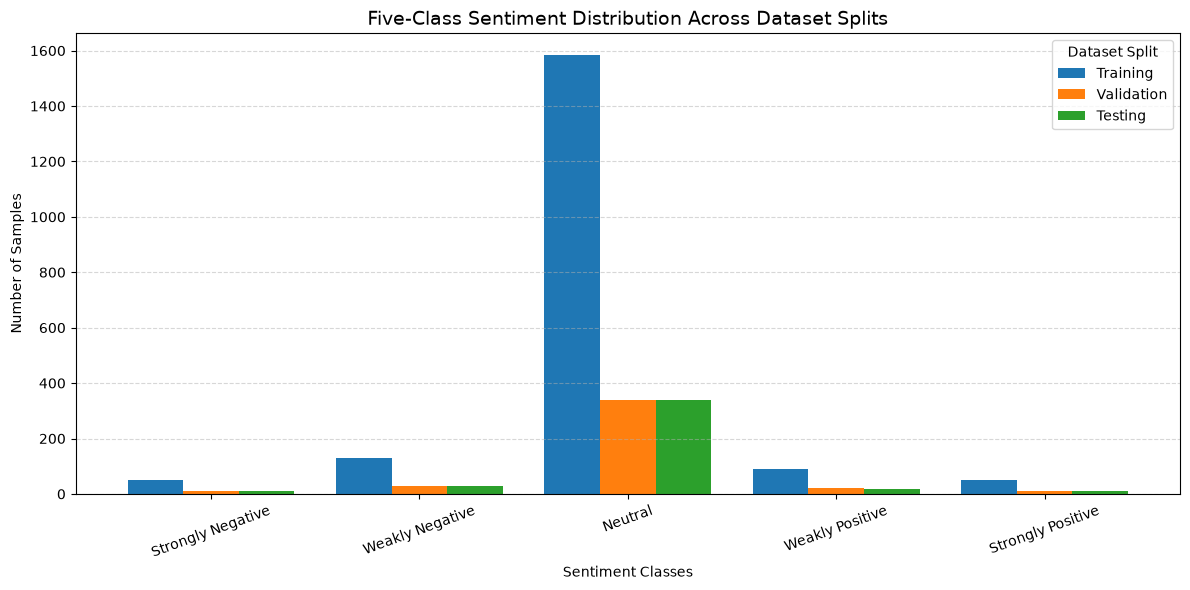

In [2]:
# Calculate class distribution
splits = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

distribution = pd.DataFrame({
    split: df["label_id"].value_counts().reindex(
        range(5), fill_value=0
    )
    for split, df in splits.items()
})

distribution.index = CLASS_NAMES

print(distribution)

# Plot graph
ax = distribution.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title(
    "Five-Class Sentiment Distribution Across Dataset Splits",
    fontsize=14
)

plt.xlabel("Sentiment Classes")
plt.ylabel("Number of Samples")
plt.xticks(rotation=20)
plt.legend(title="Dataset Split")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

     model_key loss_type  Accuracy  Macro_F1  Weighted_F1  Macro_Recall
0  hingroberta        ce    0.8333    0.1818       0.7576        0.2000
1  hingroberta     focal    0.8333    0.1818       0.7576        0.2000
2  hingroberta       wce    0.2067    0.1891       0.2274        0.4899
3        muril        ce    0.8333    0.1818       0.7576        0.2000
4        muril     focal    0.8333    0.1818       0.7576        0.2000
5        muril       wce    0.2067    0.1891       0.2274        0.4899


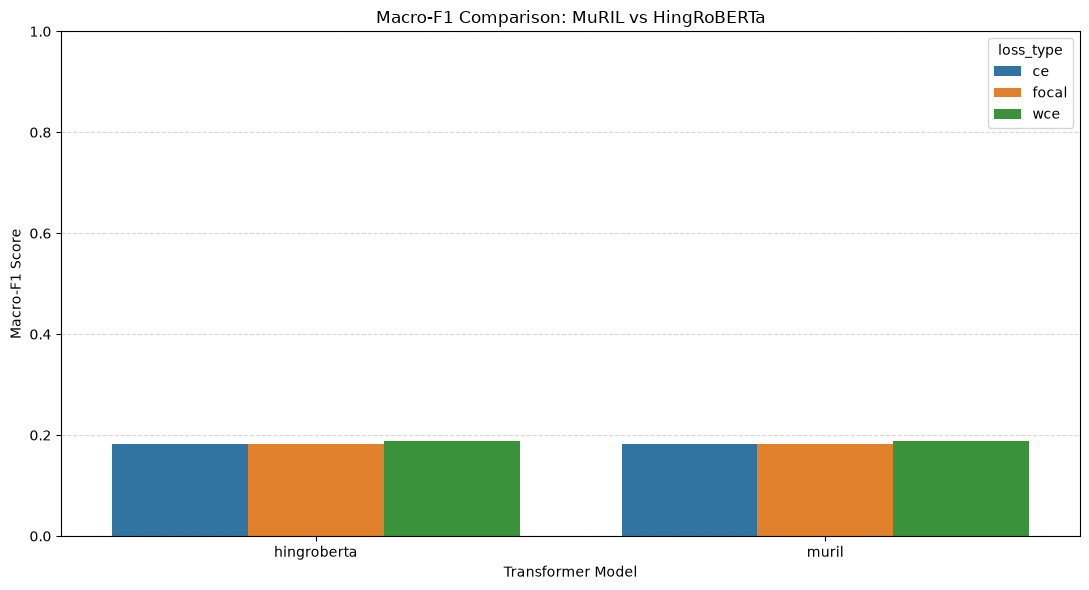

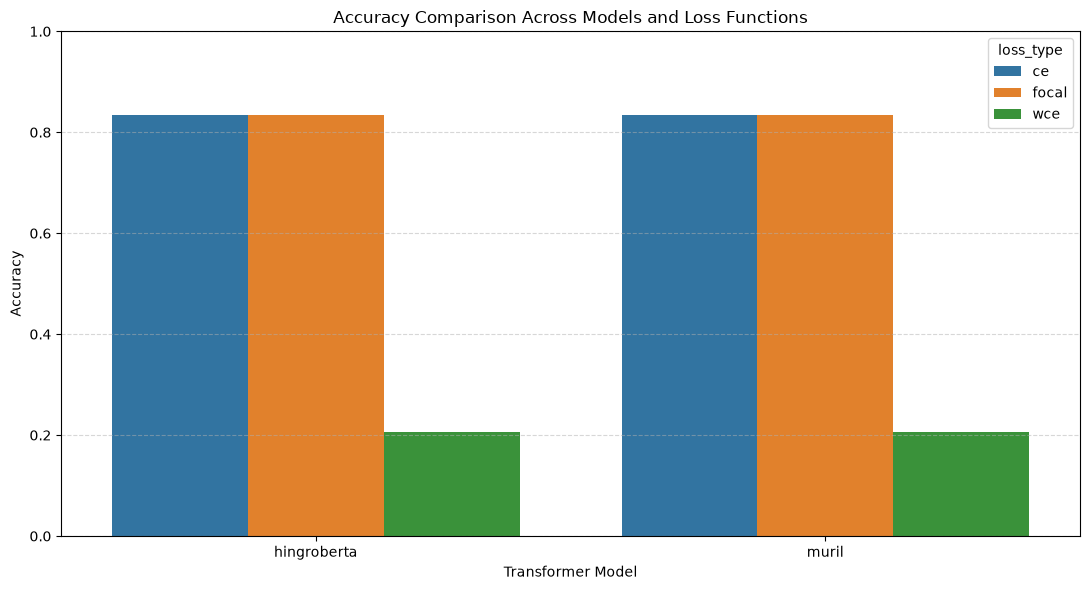

In [3]:
# Filter original Hinglish experiments
hinglish_results = results[
    results["text_type"] == "hinglish"
].copy()

# Group results
performance = hinglish_results.groupby(
    ["model_key", "loss_type"]
).agg(
    Accuracy=("accuracy", "mean"),
    Macro_F1=("macro_f1", "mean"),
    Weighted_F1=("weighted_f1", "mean"),
    Macro_Recall=("macro_recall", "mean")
).reset_index()

print(performance.round(4))

# Macro F1 comparison
plt.figure(figsize=(11, 6))

sns.barplot(
    data=performance,
    x="model_key",
    y="Macro_F1",
    hue="loss_type"
)

plt.title("Macro-F1 Comparison: MuRIL vs HingRoBERTa")
plt.xlabel("Transformer Model")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# Accuracy comparison
plt.figure(figsize=(11, 6))

sns.barplot(
    data=performance,
    x="model_key",
    y="Accuracy",
    hue="loss_type"
)

plt.title("Accuracy Comparison Across Models and Loss Functions")
plt.xlabel("Transformer Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

     model_key loss_type  Strongly_Negative_Recall  Weakly_Negative_Recall
0  hingroberta        ce                    0.0000                  0.0000
1  hingroberta     focal                    0.0000                  0.0000
2  hingroberta       wce                    0.7273                  0.5556
3        muril        ce                    0.0000                  0.0000
4        muril     focal                    0.0000                  0.0000
5        muril       wce                    0.7273                  0.5556


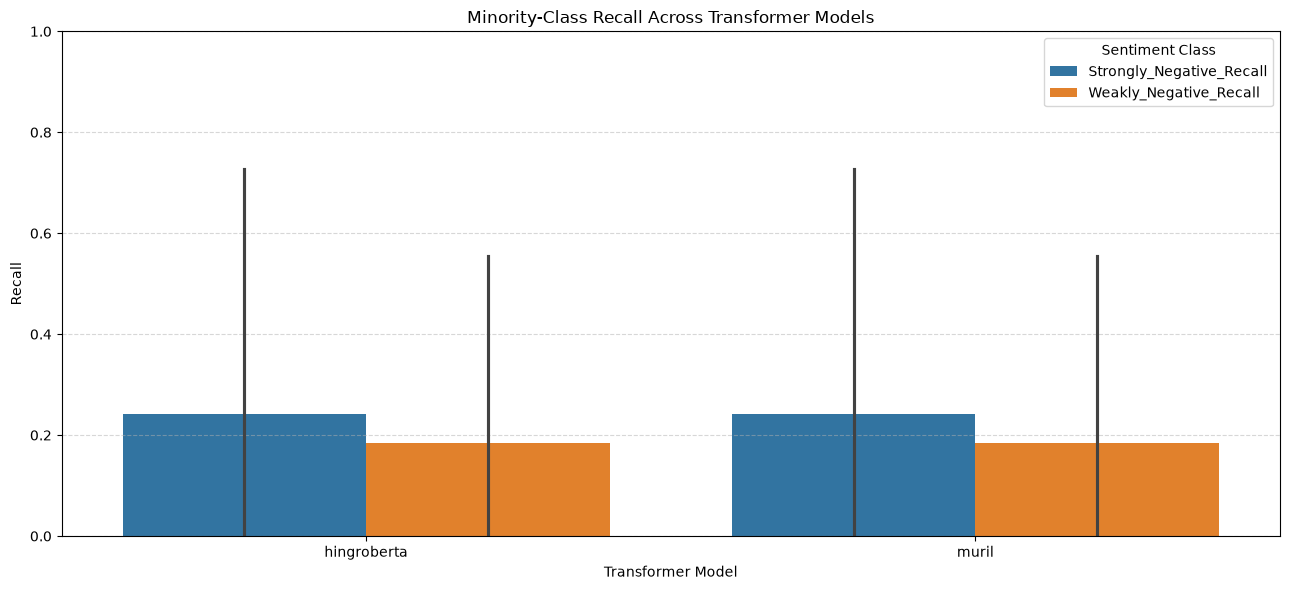

In [4]:
minority_metrics = hinglish_results.groupby(
    ["model_key", "loss_type"]
).agg(
    Strongly_Negative_Recall=("cl0_recall", "mean"),
    Weakly_Negative_Recall=("cl1_recall", "mean")
).reset_index()

print(minority_metrics.round(4))

# Prepare graph
plot_data = minority_metrics.melt(
    id_vars=["model_key", "loss_type"],
    var_name="Sentiment Class",
    value_name="Recall"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_data,
    x="model_key",
    y="Recall",
    hue="Sentiment Class"
)

plt.title("Minority-Class Recall Across Transformer Models")
plt.xlabel("Transformer Model")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

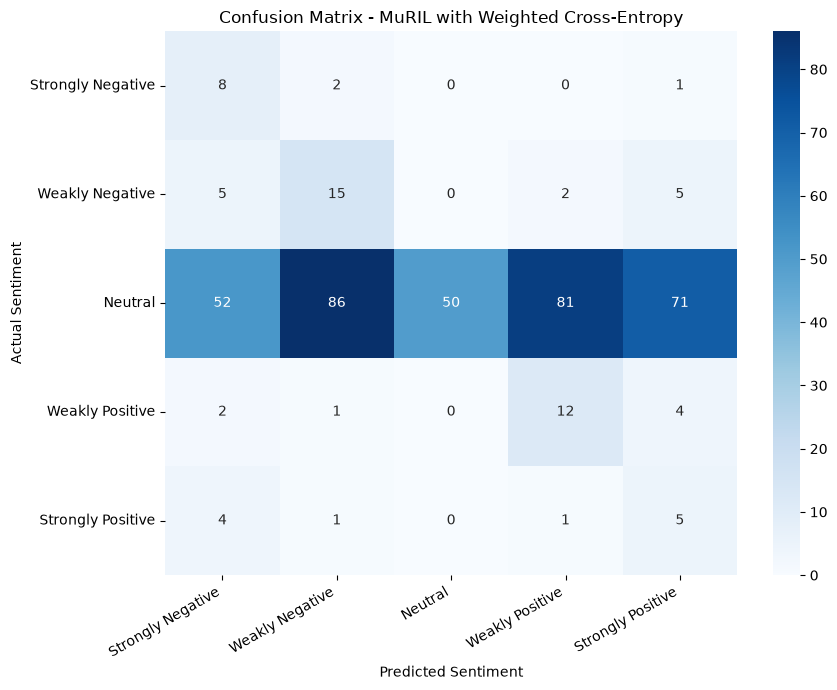


CLASSIFICATION REPORT

                   precision    recall  f1-score   support

Strongly Negative       0.11      0.73      0.20        11
  Weakly Negative       0.14      0.56      0.23        27
          Neutral       1.00      0.15      0.26       340
  Weakly Positive       0.12      0.63      0.21        19
Strongly Positive       0.06      0.45      0.10        11

         accuracy                           0.22       408
        macro avg       0.29      0.50      0.20       408
     weighted avg       0.85      0.22      0.25       408



In [5]:
# Select one experimental model
prediction_file = os.path.join(
    PREDICTIONS_DIR,
    "muril_wce_hinglish_s1_test.csv"
)

predictions = pd.read_csv(prediction_file)

y_true = predictions["y_true"]
y_pred = predictions["y_pred"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix - MuRIL with Weighted Cross-Entropy")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

     model_key loss_type text_type  macro_f1
0  hingroberta        ce   english    0.1818
1  hingroberta        ce  hinglish    0.1818
2  hingroberta     focal   english    0.1818
3  hingroberta     focal  hinglish    0.1818
4  hingroberta       wce  hinglish    0.1891
5        muril        ce   english    0.1818
6        muril        ce  hinglish    0.1818
7        muril     focal   english    0.1818
8        muril     focal  hinglish    0.1818
9        muril       wce  hinglish    0.1891


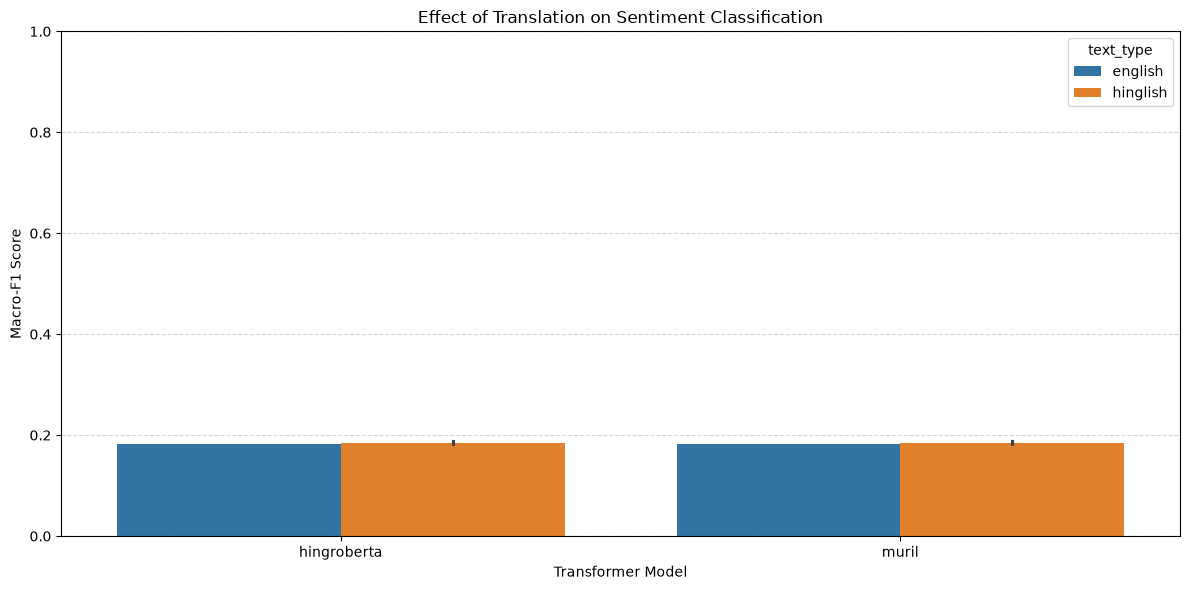

In [6]:
translation_results = results[
    results["text_type"].isin(["hinglish", "english"])
].copy()

translation_comparison = translation_results.groupby(
    ["model_key", "loss_type", "text_type"]
)["macro_f1"].mean().reset_index()

print(translation_comparison)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=translation_comparison,
    x="model_key",
    y="macro_f1",
    hue="text_type"
)

plt.title("Effect of Translation on Sentiment Classification")
plt.xlabel("Transformer Model")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Total analyzed errors: 60

Error category distribution:
error_category
neutral_weak_boundary    41
neutral_strong_skip      19
Name: count, dtype: int64


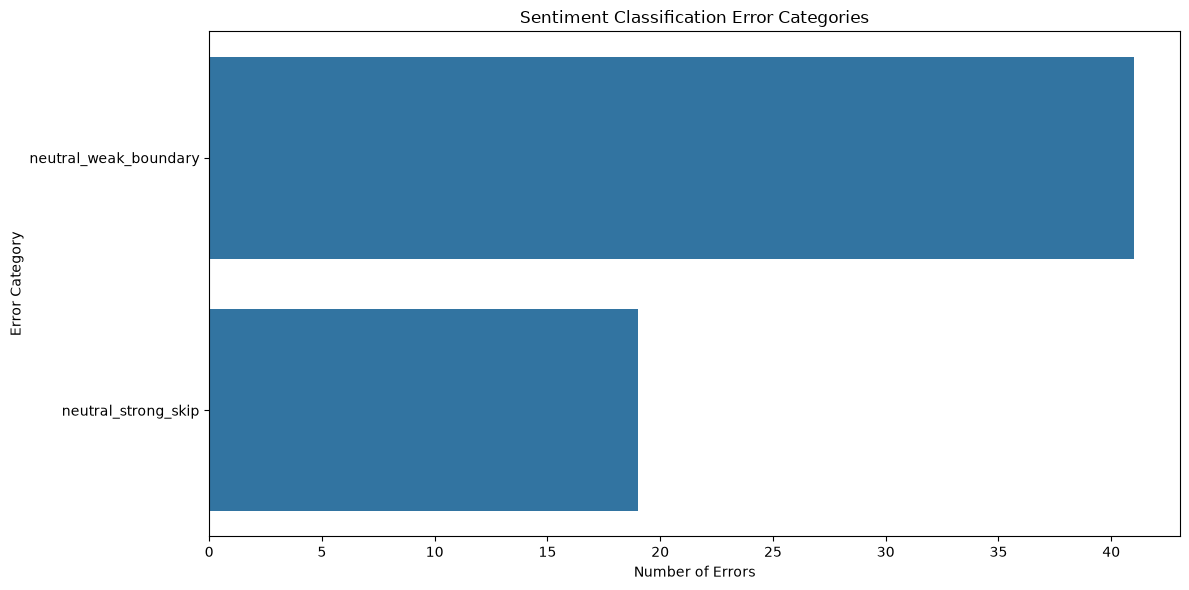

In [7]:
error_file = os.path.join(
    RESULTS_DIR,
    "error_taxonomy.csv"
)

errors = pd.read_csv(error_file)

print("Total analyzed errors:", len(errors))

print("\nError category distribution:")
print(errors["error_category"].value_counts())

plt.figure(figsize=(12, 6))

sns.countplot(
    data=errors,
    y="error_category",
    order=errors["error_category"].value_counts().index
)

plt.title("Sentiment Classification Error Categories")
plt.xlabel("Number of Errors")
plt.ylabel("Error Category")

plt.tight_layout()
plt.show()